# Assignment 2, Part 2: Pedestrians on Eindhoven Centraal

In this notebook you model the future motion of pedestrians on platforms 3 and 4 of Eindhoven Centraal. Given the first 10 observed frames of a scene, you generate the remaining 20 frames for all pedestrians using conditional flow matching with time bundling.

You implement and compare two models:
1. a model with an uninformed Gaussian prior on the future velocities;
2. a model with an informed, data dependent prior.

The focus is not on model performance, but on an architecture that fits the problem formulation and on the comparison between the two priors. Every group member must be able to explain the model design and interpret the results. The full task description is in Section 2 of the assignment PDF.

In [1]:
import contextlib
import dataclasses
import math
import pathlib
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn, Tensor
from torch.nn import functional as F
from torch.profiler import ProfilerActivity, profile, schedule
import gdown

DT = 0.5
H = 10
K = 20
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.14.0+cu132 | device: cuda


## Dataset

The dataset contains 100,000 samples. Each sample is a scene with 5 to 100 pedestrians, stored as an array of shape `(N, 30, 2)`: the 2D positions in metres of `N` pedestrians over 30 frames, spaced $\Delta t = 0.5$ s apart (15 s in total). Every pedestrian is present in all 30 frames.

The cell below downloads the data (about 290 MB).

In [2]:
drive_link = "https://drive.google.com/file/d/1sU_gti1xg2AB_SQINy_cZZm4jxE9lbIm/view?usp=drive_link"
DATA_PATH = pathlib.Path("eindhoven_centraal.pkl")

if not DATA_PATH.exists():
    print("Downloading dataset...")
    gdown.download(url=drive_link, output=str(DATA_PATH), quiet=False)
    print("Download complete:", DATA_PATH)
else:
    print("Dataset already available:", DATA_PATH)

Dataset already available: eindhoven_centraal.pkl


## Scene batching

The loader pads scenes directly to `[B, N, 30, 2]` on the CPU and builds a mask for real pedestrians.

Split IDs are sampled once with seed 13. Velocity scale and platform-position statistics are only fitted on training scenes.

In [3]:
class PedestrianDataset(torch.utils.data.Dataset):
    """Caches scenes [N, 30, 2] in meters as CPU float32 tensors."""

    def __init__(self, path: pathlib.Path):
        with path.open("rb") as f:
            self.scenes = pickle.load(f)
        for idx, scene in enumerate(self.scenes):
            if scene.shape[1:] != (H + K, 2) or not 5 <= len(scene) <= 100:
                raise ValueError(f"Unexpected scene shape {scene.shape}")
            if not np.isfinite(scene).all():
                raise ValueError("The dataset contains non-finite coordinates")
            self.scenes[idx] = torch.as_tensor(scene, dtype=torch.float32, device="cpu")

    def __len__(self) -> int:
        return len(self.scenes)

    def __getitem__(self, idx: int) -> Tensor:
        return self.scenes[idx]


def make_splits(size: int, seed: int = 13) -> dict:
    """Splits scene IDs before any preprocessing."""
    order = torch.randperm(size, generator=torch.Generator().manual_seed(seed))
    n_train, n_val = int(0.8 * size), int(0.1 * size)
    return {
        "train": order[:n_train],
        "val": order[n_train : n_train + n_val],
        "test": order[n_train + n_val:],
    }


def fit_normalization(dataset: PedestrianDataset, ids: Tensor) -> dict:
    """Fits scalar velocity RMS and anchor coordinate statistics on train IDs."""
    if ids.numel() == 0:
        raise ValueError("Normalization requires at least one training scene")
    vel_square = torch.zeros(1, dtype=torch.float64, device="cpu")
    pos_sum = torch.zeros(2, dtype=torch.float64, device="cpu")
    pos_square = torch.zeros_like(pos_sum)
    n_vel, n_pos = 0, 0  # sum_{scenes} N * 29 * 2 and sum_{scenes} N
    for idx in ids.tolist():  # please look away
        p = dataset.scenes[idx].to(dtype=torch.float64, device="cpu")  # [N, 30, 2]
        v = p.diff(dim=1) / DT  # [N, 29, 2]
        anchor = p[:, H - 1]  # [N, 2]
        vel_square += v.square().sum()  # [1,]
        n_vel += v.numel()
        pos_sum += anchor.sum(dim=0)  # [2,]
        pos_square += anchor.square().sum(dim=0)  # [2,]
        n_pos += len(anchor)
    mean = pos_sum / n_pos  # [2,]
    std = (pos_square / n_pos - mean.square()).clamp_min(1e-6).sqrt()  # [2,]
    return {
        "vel_scale": (vel_square / n_vel).sqrt().clamp_min(1e-6).item(),  # fp64
        "anchor_mean": mean.tolist(),  # [fp64, fp64]
        "anchor_std": std.tolist(),  # [fp64, fp64]
    }


def padded_batch(batch: tuple, device: torch.device) -> tuple:
    """Returns positions [B, N, 30, 2] and bool valid people [B, N]."""
    p, valid = batch[:2]
    return p.to(device, non_blocking=True), valid.to(device, non_blocking=True)


def collate_scenes(scenes: list) -> tuple:
    """Pads scenes on the CPU before pinning or transfering the dense batch."""
    n = max(len(scene) for scene in scenes)
    p = torch.zeros(len(scenes), n, H + K, 2)
    valid = torch.zeros(len(scenes), n, dtype=torch.bool)
    for i, scene in enumerate(scenes):
        p[i, :len(scene)] = scene
        valid[i, :len(scene)] = True
    people = torch.cat([torch.arange(len(scene)) + i * n for i, scene in enumerate(scenes)])
    return p, valid, people


def observed_vel(observed: Tensor) -> Tensor:
    """Returns [B, N, 10, 2]; frame-0 vel is 0."""
    return torch.cat((torch.zeros_like(observed[..., :1, :]), observed.diff(dim=-2) / DT), dim=-2)


def future_vel(pos: Tensor) -> Tensor:
    """Returns physical v10,...,v29 from positions [B, N, 30, 2]."""
    return pos[..., H - 1:, :].diff(dim=-2) / DT


def future_pos(observed: Tensor, vel: Tensor) -> Tensor:
    """Integrates physical velocities [..., N, 20, 2] starting at p9."""
    return observed[..., -1:, :] + DT * vel.float().cumsum(dim=-2)


def make_loader(
    dataset: PedestrianDataset,
    ids: Tensor,
    batch_size: int = 16,
    shuffle: bool = False,
    seed: int = 13,
    num_workers: int = 4,
) -> torch.utils.data.DataLoader:
    """Builds a deterministic scene loader without materializing graph edges."""
    subset = torch.utils.data.Subset(dataset, ids.tolist())
    return torch.utils.data.DataLoader(
        subset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_scenes,
        num_workers=num_workers,
        pin_memory=DEVICE.type == "cuda",
        persistent_workers=num_workers > 0,
        generator=torch.Generator().manual_seed(seed),
    )


def device_batches(
    loader: torch.utils.data.DataLoader,
    device: torch.device,
    prefetch: bool = True,
    pack_people: bool = False
):
    """Transfers the next pinned batch while the current batch is computing."""

    def transfer(batch):
        p, valid = padded_batch(batch, device)
        if pack_people:
            return p, valid, batch[2].to(device, non_blocking=True)
        return p, valid

    if device.type != "cuda" or not prefetch:
        for batch in loader:
            yield transfer(batch)
        return

    stream = torch.cuda.Stream(device=device)
    batches = iter(loader)

    def load_next():
        batch = next(batches, None)
        if batch is None:
            return None
        with torch.cuda.stream(stream):
            return transfer(batch)

    pending = load_next()
    while pending is not None:
        current = torch.cuda.current_stream(device)
        current.wait_stream(stream)
        batch = pending
        for tensor in batch:
            tensor.record_stream(current)
        pending = load_next()
        yield batch

## Configuration

Both priors use the same training budget and effective batch size of 128 scenes: 16 scenes per microbatch, with gradients accumulated over 8 microbatches.

In [4]:
@dataclasses.dataclass(frozen=True)
class ModelConfig:
    d_model: int = 128
    n_heads: int = 4
    n_layers: int = 4
    d_feedforward: int = 512
    bias_hidden: int = 32
    length_scale: float = 5.0


@dataclasses.dataclass(frozen=True)
class TrainConfig:
    updates: int = 50_000
    batch_size: int = 16
    accumulation: int = 8
    learning_rate: float = 3e-4
    minimum_lr: float = 3e-5
    weight_decay: float = 1e-2
    warmup_fraction: float = 0.05
    clip_norm: float = 1.0
    sigma: float = 1.0
    seed: int = 13
    validate_every: int = 500
    validation_scenes: int = 128
    use_bfloat16: bool = True
    compile_model: bool = True
    compile_mode: str = "default"
    num_workers: int = 4
    cpu_threads: int = 24
    prefetch: bool = True
    pack_people: bool = True


MODEL_CONFIG = ModelConfig()
TRAIN_CONFIG = TrainConfig()
OUTPUT_DIR = pathlib.Path("a22_results")
HEUN_STEPS = 10

SPLIT_SEED = 13
DATASET = PedestrianDataset(DATA_PATH)
SPLITS = make_splits(len(DATASET), seed=SPLIT_SEED)
NORMALIZATION = fit_normalization(DATASET, SPLITS["train"])
dataset = DATASET
print("Split seed:", SPLIT_SEED, "| Scenes:", {name: len(ids) for name, ids in SPLITS.items()})
print("Normalization:", NORMALIZATION)

Split seed: 13 | Scenes: {'train': 80000, 'val': 10000, 'test': 10000}
Normalization: {'vel_scale': 0.5200789485388121, 'anchor_mean': [-2.2609041765867968, 32.1468227205567], 'anchor_std': [2.885623329857807, 20.276915025083273]}


## Visualization
This method can be used to visualize the pedestrian trajectories. Use it to double check if your generated samples are realistic.

Make sure you download the background image: https://github.com/vlamen/ml4sci-2026/blob/main/assignments/Eindhoven_centraal_platform_3_4.png

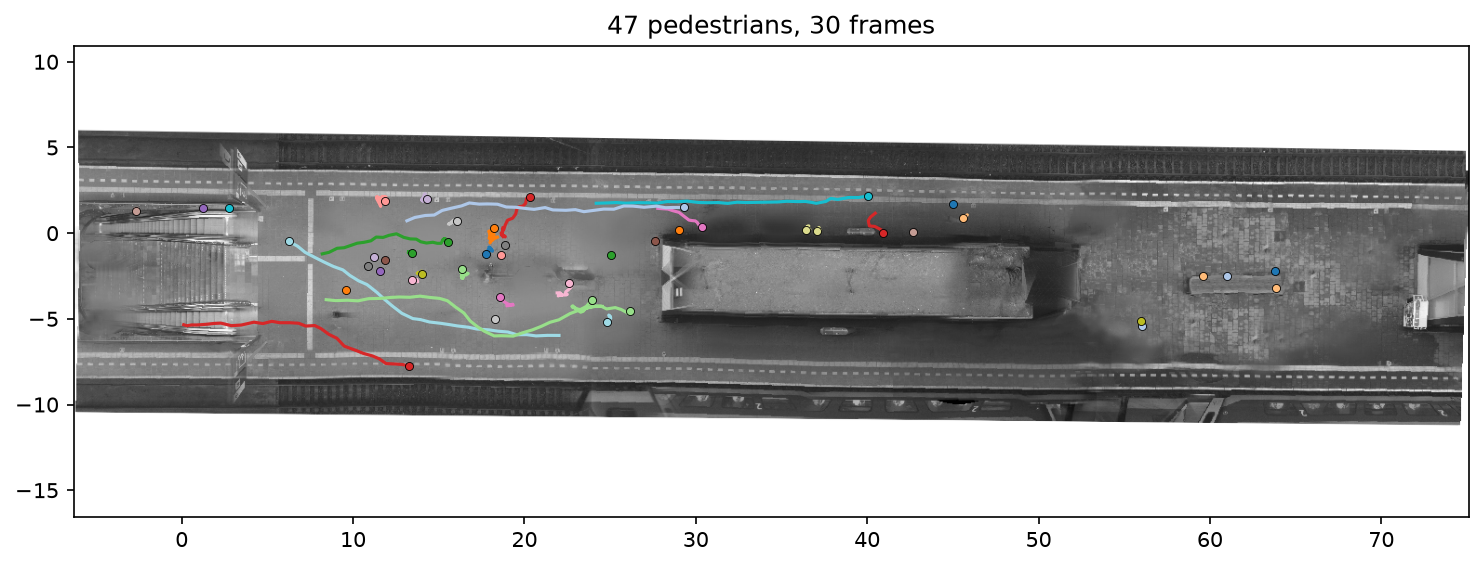

In [5]:
EXTENT = (-6.309, 75.091, -16.539, 10.909)  # (left, right, bottom, top) of the background image in metres


def plot_sample(sample, background_path="Eindhoven_centraal_platform_3_4.png", ax=None,
                cmap_name="tab20", figsize=(12, 4.5), dpi=150):
    """Plot all trajectories of one data sample on the station background.

    sample: (N, F, 2) positions of N pedestrians over F frames, as a numpy array or torch tensor.
    The x and y axes of the data are swapped to match the background image.
    Each pedestrian gets its own color; the dot marks the final position.
    """
    if isinstance(sample, Tensor):
        sample = sample.detach().cpu().numpy()
    traj = np.asarray(sample)[..., [1, 0]]  # Swap x and y

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    else:
        fig = ax.figure

    ax.imshow(plt.imread(background_path), extent=EXTENT, origin="upper", zorder=0)
    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])

    cmap = plt.get_cmap(cmap_name)
    for i, t in enumerate(traj):
        color = cmap(i % cmap.N)
        ax.plot(t[:, 0], t[:, 1], color=color, lw=1.5, zorder=1)
        ax.scatter(t[-1, 0], t[-1, 1], color=color, s=15, edgecolors="black", linewidths=0.4, zorder=2)

    ax.set_title(f"{traj.shape[0]} pedestrians, {traj.shape[1]} frames")
    return fig, ax

plot_sample(dataset[4213])
plt.show()

## Model architecture

Each person has 30 tokens. Four blocks alternate temporal attention over that person's frames and spatial attention over everybody at a frame. Physical-frame embeddings help the model understand which ten tokens are observed. Continuous flow time modulates the normalization and residual gates.

The input is relative position, normalized velocity, and scene size. An absolute last-observed-position embedding supplies platform context. Spatial logits also receive learned biases from relative position and velocity, with observed anchor and recent-velocity differences available throughout generation. Future positions are reconstructed from the current flow state at every model evaluation.

In [ ]:
class FlowTimeEmbedding(nn.Module):
    """Sinusoidal flow time features with a learned projection."""

    def __init__(self, d_model: int):
        super().__init__()
        frequencies = torch.exp(-math.log(10_000) * torch.linspace(0, 1, d_model // 2))
        self.register_buffer("frequencies", frequencies)
        self.proj = nn.Sequential(
            nn.Linear(d_model, d_model), nn.SiLU(), nn.Linear(d_model, d_model)
        )

    def forward(self, tau: Tensor) -> Tensor:
        phase = 1000 * tau[:, None].float() * self.frequencies[None]
        return self.proj(torch.cat((phase.sin(), phase.cos()), dim=-1))


class SpatialAttn(nn.Module):
    """Full attn (Ger. ACHTUNG) over people at each frame, with relative-motion logits."""

    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        assert d_model % n_heads == 0
        self._n_heads = n_heads
        self._d_h = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x: Tensor, bias: Tensor, valid: Tensor) -> Tensor:
        # x: [B, N, T, D], bias: [B, T, heads, N, N], valid: [B, N]
        q, k, v = self.qkv(x.transpose(1, 2)).chunk(3, dim=-1)
        q, k, v = [
            y.unflatten(-1, (self._n_heads, self._d_h)).transpose(2, 3)
            for y in (q, k, v)
        ]  # [B, T, heads, N, D_h]
        bias = bias.masked_fill(~valid[:, None, None, None, :], float("-inf"))
        # Fold frames into the batch so fused attn receives 4D inputs
        q, k, v = [y.flatten(0, 1).contiguous() for y in (q, k, v)]  # [B * T, heads, N, D_h]
        bias = bias.flatten(0, 1).to(q.dtype).contiguous()  # [B * T, heads, N, N]
        x = F.scaled_dot_product_attention(q, k, v, attn_mask=bias)
        x = x.unflatten(0, (len(valid), -1))  # [B, T, heads, N, D_h]
        x = x.transpose(2, 3).flatten(-2).transpose(1, 2)  # [B, N, T, D]
        return self.out_proj(x).masked_fill(~valid[..., None, None], 0)  # [B, N, T, D]


class SpatiotemporalBlock(nn.Module):
    """Temporal attn, spatial attn, and a flow-conditioned residual MLP."""

    def __init__(self, config: ModelConfig):
        super().__init__()
        d = config.d_model
        self.norms = nn.ModuleList([nn.LayerNorm(d, elementwise_affine=False) for _ in range(3)])
        self.temporal_attn = nn.MultiheadAttention(d, config.n_heads, batch_first=True)
        self.spatial_attn = SpatialAttn(d, config.n_heads)
        self.mlp = nn.Sequential(
            nn.Linear(d, config.d_feedforward),
            nn.GELU(),
            nn.Linear(config.d_feedforward, d),
        )
        self.modulation = nn.Sequential(nn.SiLU(), nn.Linear(d, 9 * d))
        nn.init.zeros_(self.modulation[-1].weight)
        nn.init.zeros_(self.modulation[-1].bias)

    def forward(
        self,
        x: Tensor,
        flow_time: Tensor,
        bias: Tensor,
        valid: Tensor,
        people: Tensor | None = None,
    ) -> Tensor:
        # x: [B, N, T, D], flow_time: [B, D], bias: [B, T, heads, N, N], valid: [B, N]
        mods = self.modulation(flow_time).chunk(9, dim=-1)  # (9 x [B, D])
        for branch in range(3):
            shift, scale, gate = [  # [B, 1, 1, D]
                m[:, None, None] for m in mods[3 * branch: 3 * branch + 3]
            ]
            h = self.norms[branch](x) * (1 + scale) + shift  # AdaLN-Zero  [B, N, T, D]
            if branch == 0:  # temporal
                # Padded rows are discarded after the residual branch
                h_flat = h.flatten(0, 1)  # [B * N, T, D]
                if people is not None:
                    h_flat = h_flat.index_select(0, people)
                out = self.temporal_attn(h_flat, h_flat, h_flat, need_weights=False)[0]
                if people is None:
                    h = out.reshape_as(h)
                else:
                    h = torch.zeros_like(h, dtype=out.dtype).flatten(0, 1)
                    h = h.index_copy(0, people, out).reshape_as(x)
            elif branch == 1:  # spatial
                h = self.spatial_attn(h, bias, valid)  # [B, N, T, D]
            else:  # mlp
                if people is None:
                    h = self.mlp(h)
                else:
                    out = self.mlp(h.flatten(0, 1).index_select(0, people))
                    h = torch.zeros_like(h, dtype=out.dtype).flatten(0, 1)
                    h = h.index_copy(0, people, out).reshape_as(x)
            x = (x + gate * h).masked_fill(~valid[..., None, None], 0)
        return x  # [B, N, T, D]


class PedestrianFlow(nn.Module):
    """Conditional vector field on normalized future velocities.

    Inputs are observed positions [B, N, 10, 2], the current flow state
    [B, N, 20, 2], flow time [B], and bool validity mask [B, N].
    The output is a flow vector [B, N, 20, 2].
    """

    def __init__(self, config: ModelConfig, normalization: dict):
        super().__init__()
        self.config = config
        d = config.d_model
        self.register_buffer("vel_scale", torch.tensor(normalization["vel_scale"]))
        self.register_buffer("anchor_mean", torch.tensor(normalization["anchor_mean"]))
        self.register_buffer("anchor_std", torch.tensor(normalization["anchor_std"]))
        self.input_proj = nn.Sequential(nn.Linear(5, d), nn.GELU(), nn.Linear(d, d))
        self.anchor_proj = nn.Sequential(nn.Linear(2, d), nn.GELU(), nn.Linear(d, d))
        self.frame_embed = nn.Parameter(torch.randn(H + K, d) * 0.02)
        self.time_embed = FlowTimeEmbedding(d)
        self.relative_bias = nn.Sequential(
            nn.Linear(8, config.bias_hidden),
            nn.GELU(),
            nn.Linear(config.bias_hidden, config.n_heads),
        )
        self.blocks = nn.ModuleList([
            SpatiotemporalBlock(config) for _ in range(config.n_layers)
        ])
        self.out_proj = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 2))
        nn.init.zeros_(self.out_proj[-1].weight)
        nn.init.zeros_(self.out_proj[-1].bias)

    def forward(
        self,
        observed: Tensor,
        x_tau: Tensor,
        tau: Tensor,
        valid: Tensor,
        people: Tensor | None = None,
    ) -> Tensor:
        assert observed.shape[-2:] == (H, 2)
        assert x_tau.shape[-2:] == (K, 2)
        assert observed.shape[:2] == x_tau.shape[:2] == valid.shape
        assert tau.shape == (len(observed),)
        observed = observed.float().masked_fill(~valid[..., None, None], 0)  # [B, N, 10, 2]
        x_tau = x_tau.float().masked_fill(~valid[..., None, None], 0)  # [B, N, 20, 2]
        anchor = observed[..., -1, :]  # [B, N, 2]
        vel_obs = observed_vel(observed) / self.vel_scale  # [B, N, 10, 2]
        vel = torch.cat([vel_obs, x_tau], dim=2)  # [B, N, 30, 2]
        pos = torch.cat([observed, future_pos(observed, x_tau * self.vel_scale)], dim=2)  # [B, N, 30, 2]
        rel_pos = (pos - anchor[:, :, None]) / self.config.length_scale  # [B, N, 30, 2]
        crowd_size = valid.sum(1).float() / 100  # [B,]
        count = crowd_size[:, None, None, None].expand(*vel.shape[:-1], 1)  # [B, N, 30, 1]
        x = self.input_proj(torch.cat([rel_pos, vel, count], dim=-1))  # [B, N, 30, D]
        x = x + self.anchor_proj((anchor - self.anchor_mean) / self.anchor_std)[:, :, None]  # [B, N, 30, D]
        x = x + self.frame_embed[None, None]  # [B, N, 30, D]
        x = x.masked_fill(~valid[..., None, None], 0)  # [B, N, 30, D]

        # Signed j-i features keep platform orientation and approaching motion
        current = torch.cat([pos / self.config.length_scale, vel], dim=-1).transpose(1, 2)  # [B, T, N, 4]
        vel_extrap = vel_obs[:, :, -3:].mean(dim=2)  # [B, N, 2]
        context = torch.cat([anchor / self.config.length_scale, vel_extrap], dim=-1)  # [B, N, 4]
        # Project each person before forming pairs: W(x_j - x_i) = Wx_j - Wx_i
        proj = self.relative_bias[0]
        current = F.linear(current, proj.weight[:, :4])  # [B, T, N, bias_hidden]
        context = F.linear(context, proj.weight[:, 4:])  # [B, N, bias_hidden]
        features = current + context[:, None]  # [B, T, N, bias_hidden]
        pair = features[:, :, None] - features[:, :, :, None]  # [B, T, N, N, bias_hidden]
        bias = self.relative_bias[2](self.relative_bias[1](pair + proj.bias))  # [B, T, N, N, heads]
        bias = bias.permute(0, 1, 4, 2, 3)  # [B, T, heads, N, N]
        flow_time = self.time_embed(tau)  # [B, D]
        for block in self.blocks:
            x = block(x, flow_time, bias, valid, people)
        return self.out_proj(x[:, :, H:]).float().masked_fill(~valid[..., None, None], 0)

with torch.random.fork_rng():
    torch.manual_seed(TRAIN_CONFIG.seed)
    test_model = PedestrianFlow(MODEL_CONFIG, NORMALIZATION)
print(f"Parameters: {sum(p.numel() for p in test_model.parameters()):,}")
del test_model

Parameters: 1,721,638


## Conditional flow matching

We train on `x_tau = (1-tau) * x0 + tau * x1` with target `x1 - x0`, where `x1` is normalized future velocity. The uninformed prior is independent Gaussian noise. The informed prior adds the mean of the last three observed velocity intervals. Both use the same Gaussian variance and the same conditioning inputs.

The loss averages within scenes, then across scenes. Sampling uses fixed-step Heun integration in flow time; physical positions use the separate 0.5-second frame spacing. Each call generates all 20 future velocities jointly.

In [ ]:
def sample_prior(
    observed: Tensor,
    valid: Tensor,
    vel_scale: float,
    informed: bool,
    sigma: float,
    generator: torch.Generator,
) -> Tensor:
    """Draws normalized future vel [B, N, 20, 2], with an optional observed mean."""
    x0 = sigma * torch.randn(
        (*valid.shape, K, 2),
        device=observed.device,
        dtype=torch.float32,
        generator=generator,
    )
    if informed:
        vel_extrap = observed_vel(observed)[..., -3:, :].mean(dim=-2)  # [B, N, 2]
        x0 = x0 + vel_extrap[..., None, :] / vel_scale
    return x0.masked_fill(~valid[..., None, None], 0)  # [B, N, 20, 2]


def scene_mse(pred: Tensor, target: Tensor, valid: Tensor) -> Tensor:
    """Averages squared error within scenes, then weights scenes equally."""
    error = (pred.float() - target.float()).square().mean(dim=(-1, -2))  # [B, N]
    return ((error * valid).sum(dim=1) / valid.sum(dim=1)).mean()


def flow_loss(
    model: PedestrianFlow,
    pos: Tensor,
    valid: Tensor,
    informed: bool,
    sigma: float,
    generator: torch.Generator,
    people: Tensor | None = None,
) -> Tensor:
    """Computes straight-path CFM loss with independent x0/x1 and one tau per scene."""
    observed = pos[:, :, :H]  # [B, N, 10, 2]
    x1 = future_vel(pos) / model.vel_scale  # [B, N, 20, 2]
    x0 = sample_prior(observed, valid, model.vel_scale, informed, sigma, generator)
    tau = torch.rand(len(pos), device=pos.device, generator=generator)  # [B,]
    t = tau[:, None, None, None]  # [B, 1, 1, 1]
    x_tau = (1 - t) * x0 + t * x1  # [B, N, 20, 2]
    return scene_mse(model(observed, x_tau, tau, valid, people), x1 - x0, valid)


@torch.no_grad()
def heun(field, x0: Tensor, steps: int) -> Tensor:
    """Integrates dx/dtau = field(x, tau) over [0, 1] with 2 * steps evaluations."""
    if steps < 1:
        raise ValueError("Heun needs at least one step")
    x = x0.float().clone()
    dtau = 1 / steps
    for step in range(steps):
        first = field(x, step * dtau).float()
        second = field(x + dtau * first, (step + 1) * dtau).float()
        x = x + 0.5 * dtau * (first + second)
    if not torch.isfinite(x).all():
        raise FloatingPointError("Non-finite sampled velocities")
    return x


@torch.no_grad()
def sample_future(
    model: PedestrianFlow,
    observed: Tensor,
    valid: Tensor,
    informed: bool,
    generator: torch.Generator,
    steps: int = 10,
    sigma: float = 1.0,
) -> Tensor:
    """Returns one joint future vel [B, N, 20, 2] in m/s."""
    model.eval()
    x0 = sample_prior(observed, valid, model.vel_scale, informed, sigma, generator)

    def field(x: Tensor, tau: float) -> Tensor:
        t = torch.full((len(x),), tau, device=x.device)  # [B,]
        return model(observed, x, t, valid)

    return heun(field, x0, steps) * model.vel_scale


def lr_multiplier(update: int, config: TrainConfig) -> float:
    """Returns the LR multiplier for a zero-based update: warmup, then cosine decay."""
    warmup = max(1, int(config.warmup_fraction * config.updates))
    if update < warmup:
        return (update + 1) / warmup
    progress = min(1.0, (update - warmup) / max(config.updates - warmup - 1, 1))
    floor = config.minimum_lr / config.learning_rate
    return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * progress))


@torch.no_grad()
def validation_loss(
    model: PedestrianFlow,
    dataset: PedestrianDataset,
    ids: Tensor,
    informed: bool,
    config: TrainConfig,
) -> float:
    """Computes scene-averaged CFM loss with a fixed validation RNG."""
    model.eval()
    device = next(model.parameters()).device
    generator = torch.Generator(device=device).manual_seed(config.seed + 3)
    total, count = torch.zeros((), device=device), 0
    loader = make_loader(dataset, ids[:config.validation_scenes], config.batch_size)
    for pos, valid in device_batches(loader, device, config.prefetch):
        total += flow_loss(model, pos, valid, informed, config.sigma, generator) * len(pos)
        count += len(pos)
    return (total / count).item()


def train_model(
    informed: bool,
    config: TrainConfig | None = None,
    output_dir: pathlib.Path | None = None,
    dataset: PedestrianDataset | None = None,
    splits: dict | None = None,
    normalization: dict | None = None,
    model_config: ModelConfig | None = None,
    device: torch.device | None = None,
    profiler=None,
) -> tuple:
    """Trains and saves the best-validation weights."""
    config = TRAIN_CONFIG if config is None else config
    torch.set_num_threads(config.cpu_threads)
    output_dir = OUTPUT_DIR if output_dir is None else pathlib.Path(output_dir)
    dataset = DATASET if dataset is None else dataset
    splits = SPLITS if splits is None else splits
    normalization = NORMALIZATION if normalization is None else normalization
    model_config = MODEL_CONFIG if model_config is None else model_config
    device = DEVICE if device is None else device
    assert config.updates > 0 and config.accumulation > 0 and config.batch_size > 0
    assert config.validate_every > 0 and config.validation_scenes > 0
    assert len(splits["train"]) > 0 and len(splits["val"]) > 0
    output_dir.mkdir(parents=True, exist_ok=True)
    label = "informed" if informed else "uninformed"
    checkpoint_path = output_dir / f"{label}_best.pt"
    # The same seed gives both priors identical fresh initial weights
    with torch.random.fork_rng():
        torch.manual_seed(config.seed)
        model = PedestrianFlow(model_config, normalization)
    model = model.to(device)
    field = model
    if config.compile_model and device.type == "cuda":
        field = torch.compile(model, fullgraph=True, dynamic=True, mode=config.compile_mode)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay,
        fused=device.type == "cuda",
    )
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda update: lr_multiplier(update, config)
    )
    loader = make_loader(
        dataset,
        splits["train"],
        config.batch_size,
        shuffle=True,
        seed=config.seed + 1,
        num_workers=config.num_workers,
    )
    batches = iter(device_batches(loader, device, config.prefetch, config.pack_people))
    generator = torch.Generator(device=device).manual_seed(config.seed + 2)
    best_loss, best_checkpoint = float("inf"), None
    history = []
    use_amp = config.use_bfloat16 and device.type == "cuda" and torch.cuda.is_bf16_supported()
    record = (
        torch.profiler.record_function
        if profiler is not None
        else lambda name: contextlib.nullcontext()
    )
    start = time.perf_counter()
    for update in range(config.updates):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        train_loss = torch.zeros((), device=device)
        for _ in range(config.accumulation):
            with record("load_batch"):
                try:
                    batch = next(batches)
                except StopIteration:
                    batches = iter(
                        device_batches(loader, device, config.prefetch, config.pack_people)
                    )
                    batch = next(batches)
            pos, valid = batch[:2]  # [B, N, 30, 2], [B, N]
            people = batch[2] if config.pack_people else None  # Flat indices of valid people
            with record("forward_and_loss"):
                with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_amp):
                    loss = flow_loss(field, pos, valid, informed, config.sigma, generator, people)
            with record("backward"):
                (loss / config.accumulation).backward()
            train_loss += loss.detach() / config.accumulation
        with record("optimizer_update"):
            grad_norm = nn.utils.clip_grad_norm_(
                model.parameters(),
                config.clip_norm,
                error_if_nonfinite=False,
                foreach=True,
            )
            train_loss, grad_norm = torch.stack((train_loss, grad_norm)).tolist()
            if not math.isfinite(train_loss) or not math.isfinite(grad_norm):
                raise FloatingPointError(f"Non-finite loss or gradients at update {update}")
            optimizer.step()
            scheduler.step()
        step = update + 1
        row = {"step": step, "train": train_loss}
        if step % config.validate_every == 0 or step == config.updates:
            val_loss = validation_loss(model, dataset, splits["val"], informed, config)
            if not math.isfinite(val_loss):
                raise FloatingPointError(f"Non-finite validation loss at step {step}")
            row["val"] = val_loss
            print(f"{label} | step {step} | train {train_loss:.5f} | val {val_loss:.5f}")
            if val_loss < best_loss:
                best_loss = val_loss
                best_checkpoint = {
                    "model": {
                        key: value.detach().cpu().clone()
                        for key, value in model.state_dict().items()
                    },
                    "step": step,
                    "val_loss": best_loss,
                    "informed": informed,
                    "config": dataclasses.asdict(config),
                    "model_config": dataclasses.asdict(model_config),
                    "normalization": normalization,
                    "splits": {key: ids.cpu().clone() for key, ids in splits.items()},
                    "trained_updates": step,
                    "seconds": time.perf_counter() - start,
                }
                torch.save(best_checkpoint, checkpoint_path)
        history.append(row)
        if profiler is not None:
            profiler.step()
    best_checkpoint.update(
        trained_updates=config.updates,
        seconds=time.perf_counter() - start,
        history=history,
    )
    torch.save(best_checkpoint, checkpoint_path)
    return model, history


def load_best(
    informed: bool,
    output_dir: pathlib.Path | None = None,
    device: torch.device | None = None,
) -> tuple:
    """Loads the best-validation model in eval mode."""
    output_dir = OUTPUT_DIR if output_dir is None else pathlib.Path(output_dir)
    device = DEVICE if device is None else device
    label = "informed" if informed else "uninformed"
    saved = torch.load(output_dir / f"{label}_best.pt", map_location="cpu", weights_only=False)
    if saved["informed"] != informed:
        raise ValueError("Checkpoint prior does not match the requested model")
    model = PedestrianFlow(ModelConfig(**saved["model_config"]), saved["normalization"])
    state = {}
    for key, value in saved["model"].items():
        if key == "frame_embedding":
            key = "frame_embed"
        elif key.startswith("time_embedding."):
            key = key.replace("time_embedding.", "time_embed.", 1)
        if key in state:
            raise ValueError(f"Duplicate checkpoint parameter after renaming: {key}")
        state[key] = value
    model.load_state_dict(state)
    return model.to(device).eval(), saved

## Profile

In [8]:
def profile_training(output_dir: pathlib.Path, config: TrainConfig) -> None:
    """Profiles a short training run after compilation and shape warmup."""
    output_dir.mkdir(parents=True, exist_ok=True)
    activities = [ProfilerActivity.CPU]
    if DEVICE.type == "cuda":
        activities.append(ProfilerActivity.CUDA)

    def show_profile(prof) -> None:
        averages = prof.key_averages()
        print(averages.table(sort_by="self_cpu_time_total", row_limit=20))
        if DEVICE.type == "cuda":
            print(averages.table(sort_by="self_cuda_time_total", row_limit=20))
        prof.export_chrome_trace(str(output_dir / "training_trace.json"))

    with profile(
        activities=activities,
        schedule=schedule(wait=5, warmup=1, active=3, repeat=1),
        on_trace_ready=show_profile,
    ) as prof:
        train_model(
            informed=False,
            config=config,
            output_dir=output_dir / "checkpoints",
            profiler=prof,
        )

PROFILE_DIR = pathlib.Path("foo_profile/optimized")
profile_config = dataclasses.replace(TRAIN_CONFIG, updates=12, validate_every=500)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE))
profile_training(PROFILE_DIR, profile_config)

PyTorch: 2.14.0+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


USDT:2026-10-14 22:33:05 1898734:1898734 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-14 22:33:05 1898734:1898734 SyncActivityProfilerHandler.cpp:46] profiler_stop


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                               backward        36.56%     186.581ms        37.45%     191.092ms       7.962ms       0.000us         0.00%      40.832us       1.701us            24  
## Call CompiledFxGraph fz2be5hrqktar23flmxs6dvhhpvi...         8.60%      43.889ms        21.53%     109.845ms       6.103ms       0.000us         0.00%     120.192ms       6.677ms            18  
         

## Paired training

Both priors use the same initialization seed, shuffled data order and flow-noise seed.

The lowest validation loss within each run is the saved model: `uninformed_best.pt` or `informed_best.pt`. The model returned by `train_model` is the last update's weights.

In [9]:
uninformed_model, uninformed_history = train_model(informed=False)
del uninformed_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
informed_model, informed_history = train_model(informed=True)
del informed_model

uninformed | step 500 | train 0.69483 | val 0.64736
uninformed | step 1000 | train 0.45982 | val 0.46542
uninformed | step 1500 | train 0.50514 | val 0.44564
uninformed | step 2000 | train 0.44891 | val 0.43956
uninformed | step 2500 | train 0.45482 | val 0.43319
uninformed | step 3000 | train 0.50118 | val 0.42970
uninformed | step 3500 | train 0.42619 | val 0.42758
uninformed | step 4000 | train 0.46631 | val 0.42415
uninformed | step 4500 | train 0.48392 | val 0.42031
uninformed | step 5000 | train 0.42063 | val 0.41971
uninformed | step 5500 | train 0.47941 | val 0.41797
uninformed | step 6000 | train 0.42684 | val 0.41744
uninformed | step 6500 | train 0.44077 | val 0.41765
uninformed | step 7000 | train 0.37442 | val 0.41716
uninformed | step 7500 | train 0.46274 | val 0.41777
uninformed | step 8000 | train 0.46480 | val 0.41450
uninformed | step 8500 | train 0.40526 | val 0.41490
uninformed | step 9000 | train 0.40790 | val 0.41217
uninformed | step 9500 | train 0.42237 | val 0.

In [8]:
uninformed_model, uninformed_saved = load_best(informed=False)
informed_model, informed_saved = load_best(informed=True)
uninformed_history = uninformed_saved["history"]
informed_history = informed_saved["history"]
for label, saved in (("uninformed", uninformed_saved), ("informed", informed_saved)):
    print(f"{label} | best step {saved['step']} | val {saved['val_loss']:.5f}")

uninformed | best step 45500 | val 0.38785
informed | best step 50000 | val 0.38951


## Evaluation

For every test sample, generate $M = 20$ futures with each model. All metrics are computed on frames 10 to 29 only.

**Pointwise metrics.** Report ADE, FDE, $\text{min}_{20}$ ADE and $\text{min}_{20}$ FDE. ADE and FDE are averaged over all pedestrians, samples and generated futures. For the $\text{min}_{20}$ metrics, the best future is selected per data sample based on the error averaged over all its pedestrians, not per pedestrian.

**Distributional metrics.** Plot histogram densities of the ground truth and both models for velocity magnitude, acceleration magnitude, tortuosity and distance to the closest neighbour within the same frame.

The exact definitions are given in the evaluation section of the assignment PDF. You are of course allowed to use code from the practicals

In [ ]:
def displacement_errors(pred: Tensor, target: Tensor, valid: Tensor) -> Tensor:
    """Returns ADE/FDE [B, 2] for one whole-scene future."""
    distance = (pred.float() - target.float()).norm(dim=-1)  # [B, N, K]
    count = valid.sum(dim=1)  # [B,]
    ade = (distance.mean(dim=-1) * valid).sum(dim=1) / count
    fde = (distance[..., -1] * valid).sum(dim=1) / count
    return torch.stack((ade, fde), dim=-1)


def kinematics(observed: Tensor, vel: Tensor, valid: Tensor) -> dict:
    """Returns speed, accel, tortuosity and nearest-neighbour distance for valid people."""
    pos = future_pos(observed, vel)  # [B, N, 20, 2]
    last_vel = observed_vel(observed)[..., -1:, :]  # [B, N, 1, 2]
    accel = torch.cat([last_vel, vel], dim=-2).diff(dim=-2) / DT  # [B, N, 20, 2]
    speed = vel.norm(dim=-1)  # [B, N, 20]
    path_length = DT * speed.sum(dim=-1)
    displacement = (pos[..., -1, :] - observed[..., -1, :]).norm(dim=-1)
    tortuosity = path_length / displacement.clamp_min(0.01)  # [B, N]
    points = pos.transpose(1, 2)  # [B, K, N, 2]
    distances = torch.cdist(points.float(), points.float())
    diagonal = torch.eye(valid.shape[1], device=valid.device, dtype=torch.bool)
    distances = distances.masked_fill(diagonal[None, None], float("inf"))
    distances = distances.masked_fill(~valid[:, None, None, :], float("inf"))
    nearest = distances.amin(dim=-1).transpose(1, 2)  # [B, N, K]
    return {
        "speed": speed[valid],
        "acceleration": accel.norm(dim=-1)[valid],
        "tortuosity": tortuosity[valid],
        "nearest": nearest[valid],
    }


class Histogram:
    """Counts values in each bin."""

    def __init__(self, edges: Tensor):
        self.edges = torch.as_tensor(edges, dtype=torch.float64, device="cpu")
        self.counts = torch.zeros(len(self.edges) - 1, dtype=torch.int64, device="cpu")
        self.total = 0
        self.outside = 0

    def update(self, values: Tensor) -> None:
        values = values.detach().float().cpu().double().flatten()
        if not torch.isfinite(values).all():
            raise FloatingPointError("Non-finite histogram values")
        counts, _ = torch.histogram(values, bins=self.edges)
        self.counts += counts.to(dtype=torch.int64)
        self.total += values.numel()
        self.outside += values.numel() - int(counts.sum().item())

    def result(self) -> dict:
        return {
            "edges": self.edges,
            "counts": self.counts,
            "total": self.total,
            "outside_fraction": self.outside / max(self.total, 1),
            "density": self.counts / (max(self.total, 1) * self.edges.diff()),
        }


def histogram_edges(dataset: PedestrianDataset, train_ids: Tensor) -> dict:
    """Fits common histogram ranges on a fixed training subset."""
    values = {name: [] for name in ("speed", "acceleration", "tortuosity", "nearest")}
    for batch in make_loader(dataset, train_ids[:512], batch_size=4):
        pos, valid = padded_batch(batch, torch.device("cpu"))
        for name, value in kinematics(pos[:, :, :H], future_vel(pos), valid).items():
            values[name].append(value.flatten())
    edges = {}
    for name, pieces in values.items():
        samples = torch.cat(pieces)
        quantile = torch.quantile(samples.double(), 0.995).to(samples.dtype)
        upper = max(quantile.item(), 0.1)
        edges[name] = torch.linspace(
            0, 2 if name == "nearest" else upper, 81, dtype=torch.float64, device="cpu"
        )
    return edges


@torch.no_grad()
def evaluate_model(
    model: PedestrianFlow,
    dataset: PedestrianDataset,
    ids: Tensor,
    informed: bool,
    edges: dict,
    steps: int = 10,
    sigma: float = 1.0,
    seed: int = 2026,
    batch_size: int = 4,
    include_truth: bool = False,
) -> dict:
    """Evaluates 20 futures per scene, weighting scenes equally."""
    device = next(model.parameters()).device
    generator = torch.Generator(device=device).manual_seed(seed)
    histograms = {name: Histogram(bins) for name, bins in edges.items()}
    truth = {name: Histogram(bins) for name, bins in edges.items()}
    totals = torch.zeros(4, dtype=torch.float64)
    count = 0
    start = time.perf_counter()
    for batch in make_loader(dataset, ids, batch_size):
        pos, valid = padded_batch(batch, device)
        observed, target = pos[:, :, :H], pos[:, :, H:]  # [B, N, 10, 2], [B, N, 20, 2]
        if include_truth:
            for name, values in kinematics(observed, future_vel(pos), valid).items():
                truth[name].update(values)
        mean_error = torch.zeros(len(pos), 2, device=device, dtype=torch.float64)  # [B, 2]
        best_error = torch.full((len(pos), 2), float("inf"), device=device)
        for _ in range(20):
            vel = sample_future(model, observed, valid, informed, generator, steps, sigma)
            pred = future_pos(observed, vel)  # [B, N, 20, 2]
            errors = displacement_errors(pred, target, valid)  # [B, 2]
            mean_error += errors.double() / 20
            best_error = torch.minimum(best_error, errors)
            for name, values in kinematics(observed, vel, valid).items():
                histograms[name].update(values)
        totals += torch.cat([mean_error, best_error.double()], dim=1).sum(dim=0).cpu()
        count += len(pos)
    if count == 0:
        raise ValueError("Cannot evaluate an empty split")
    names = ("ADE", "FDE", "min20 ADE", "min20 FDE")
    return {
        "metrics": dict(zip(names, (totals / count).tolist(), strict=True)),
        "histograms": {name: value.result() for name, value in histograms.items()},
        "truth": {name: value.result() for name, value in truth.items()} if include_truth else None,
        "scenes": count,
        "futures": 20,
        "steps": steps,
        "seed": seed,
        "seconds": time.perf_counter() - start,
        "scene_ids": ids.clone(),
    }


def evaluate_pair(
    output_dir: pathlib.Path = OUTPUT_DIR,
    steps: int = 10,
    config: TrainConfig | None = None,
) -> dict:
    """Evaluates both priors on the test split."""
    config = TRAIN_CONFIG if config is None else config
    assert len(DATASET) == 100_000 and len(SPLITS["test"]) >= 1000
    uninformed_model, uninformed_saved = load_best(False, output_dir)
    informed_model, informed_saved = load_best(True, output_dir)
    for saved in (uninformed_saved, informed_saved):
        assert saved["trained_updates"] == config.updates
        assert saved["config"] == dataclasses.asdict(config)
        assert saved["model_config"] == dataclasses.asdict(MODEL_CONFIG)
        assert saved["normalization"] == NORMALIZATION
        for key, ids in SPLITS.items():
            assert torch.equal(saved["splits"][key].cpu(), ids.cpu())
    edges = histogram_edges(DATASET, SPLITS["train"])
    results = {}
    for informed, model in ((False, uninformed_model), (True, informed_model)):
        label = "informed" if informed else "uninformed"
        results[label] = evaluate_model(
            model,
            DATASET,
            SPLITS["test"],
            informed,
            edges,
            steps,
            uninformed_saved["config"]["sigma"],
            include_truth=not informed,
        )
        saved = informed_saved if informed else uninformed_saved
        results[label]["training_seconds"] = saved["seconds"]
        results[label]["updates"] = saved["trained_updates"]
        results[label]["best_step"] = saved["step"]
        results[label]["validation_loss"] = saved["val_loss"]
    torch.save(results, output_dir / "evaluation.pt")
    return results

## Comparison

Reporting ADE, FDE, min20 ADE and min20 FDE for both models, together with the four histograms. Errors weight scenes equally; the best future is selected per scene. Histogram densities retain mass outside the displayed range. Ground truth is counted once per scene, and nearest-neighbour distances are shown from 0 to 2 m.

              ADE    FDE  min20 ADE  min20 FDE
uninformed 0.8522 1.7256     0.5732     1.0634
informed   0.8305 1.6724     0.5693     1.0551


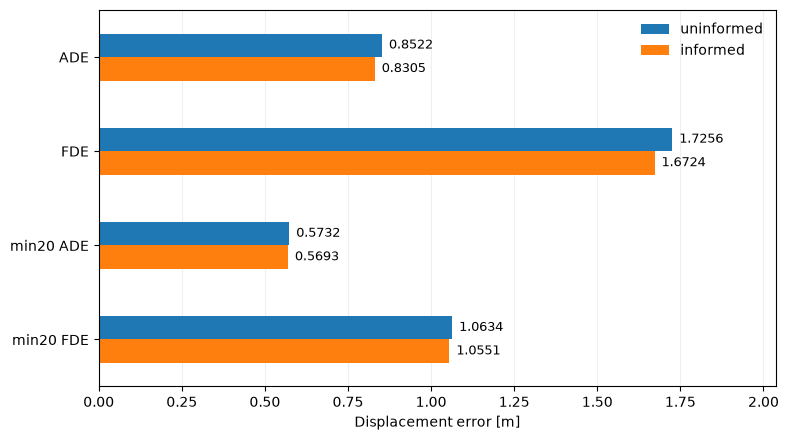

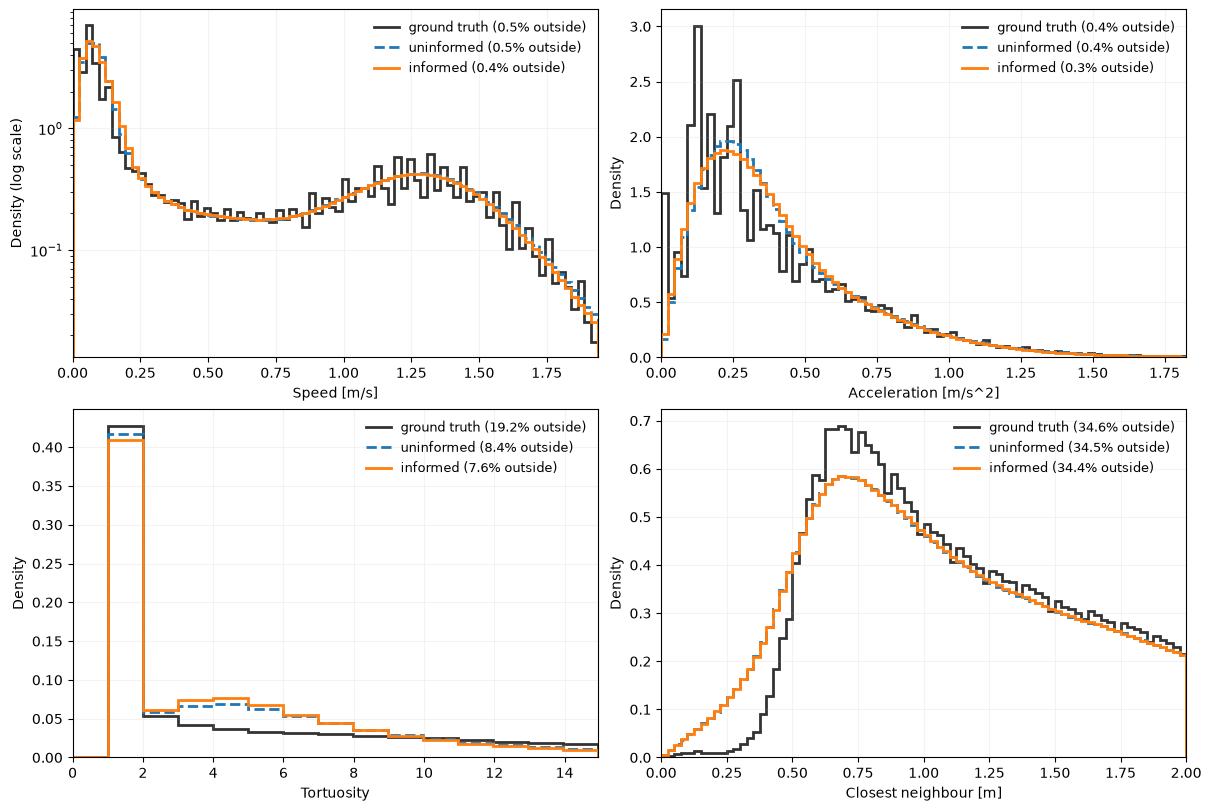

In [13]:
def plot_results(results: dict) -> pd.DataFrame:
    """Plots pointwise errors and physical distributions."""
    colors = {"ground truth": "0.2", "uninformed": "tab:blue", "informed": "tab:orange"}
    table = pd.DataFrame(
        {label: results[label]["metrics"] for label in ("uninformed", "informed")}
    ).T
    print(table.to_string(float_format=lambda value: f"{value:.4f}"))

    ax = table.T.plot.barh(
        figsize=(8, 4.5), color=[colors[label] for label in table.index]
    )
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.4f", padding=5, fontsize=9)
    ax.set(xlabel="Displacement error [m]", ylabel="", xlim=(0, table.max().max() * 1.18))
    ax.invert_yaxis()
    ax.legend(frameon=False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

    distributions = {
        "ground truth": results["uninformed"]["truth"],
        "uninformed": results["uninformed"]["histograms"],
        "informed": results["informed"]["histograms"],
    }
    labels = {
        "speed": "Speed [m/s]",
        "acceleration": "Acceleration [m/s^2]",
        "tortuosity": "Tortuosity",
        "nearest": "Closest neighbour [m]",
    }
    _, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    for ax, name in zip(axes.flat, labels, strict=True):
        for label, values in distributions.items():
            hist = values[name]
            end = len(hist["density"])
            if name == "tortuosity":
                end = np.searchsorted(hist["edges"], 15, side="right") - 1
            outside = 1 - float(hist["counts"][:end].sum()) / hist["total"]
            ax.stairs(
                hist["density"][:end], hist["edges"][:end + 1],
                color=colors[label], lw=2,
                linestyle="--" if label == "uninformed" else "-",
                label=f"{label} ({outside:.1%} outside)",
            )
        ax.set(xlabel=labels[name], ylabel="Density", xlim=(0, float(hist["edges"][end])))
        if name == "speed":
            ax.set_yscale("log")
            ax.set_ylabel("Density (log scale)")
        else:
            ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=9)
        ax.grid(alpha=0.15)
    plt.show()
    return table


results = torch.load(OUTPUT_DIR / "evaluation.pt", map_location="cpu", weights_only=False)
metric_table = plot_results(results)

Stored data: list of ndarray | dtype: float16
Scenes: 100,000 | trajectories: 2,358,008
Shape: [N, 30, 2] | N: 5..100
Positions in meters | frame spacing: 0.5 s | cached dtype: torch.float32


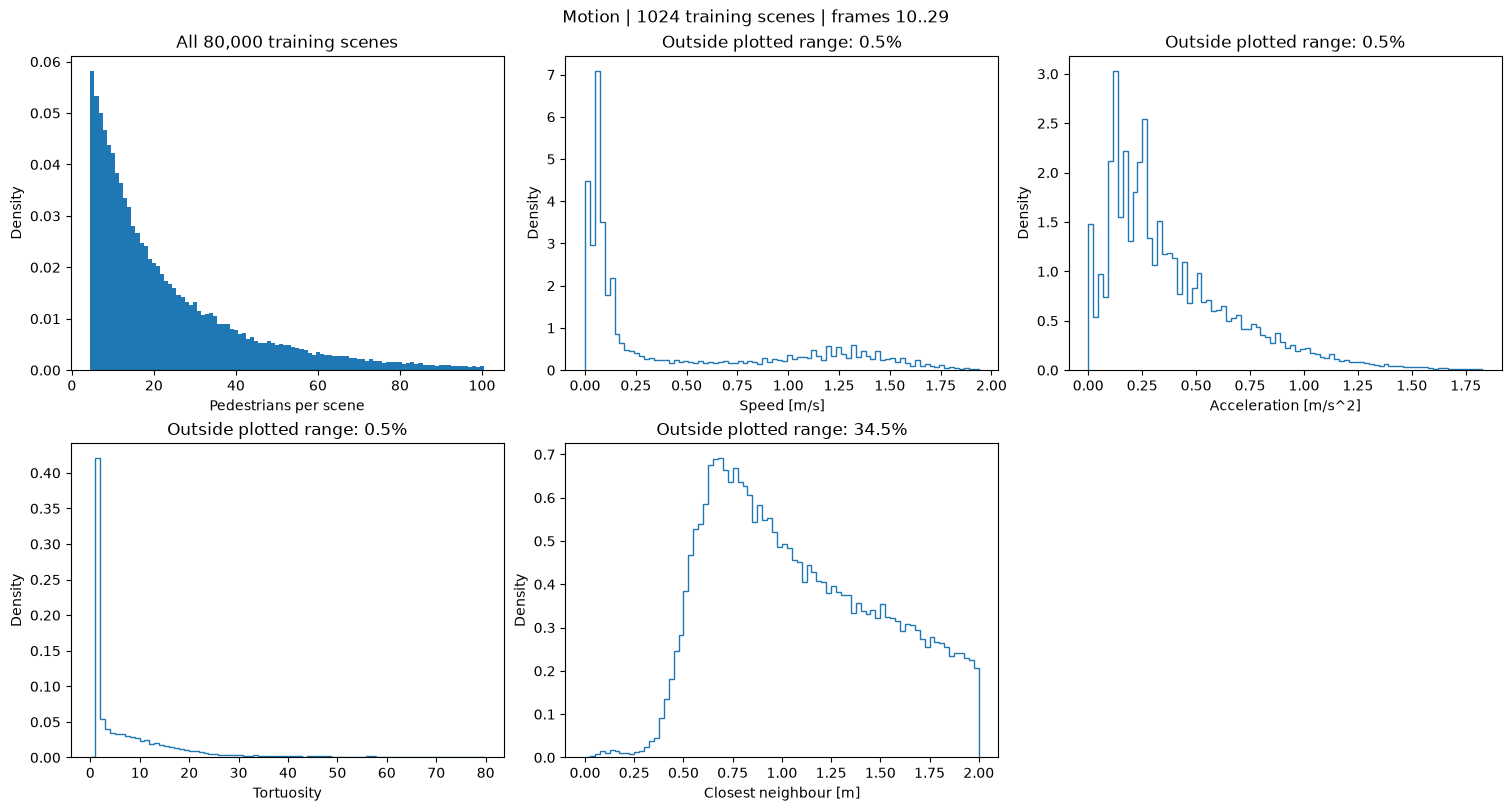

               mean  median     p95      max
speed        0.4689  0.1260  1.5195   4.7543
acceleration 0.4029  0.3001  1.0388  13.6955
tortuosity   9.4627  3.6092 37.8549 278.1362
nearest      2.2991  1.4461  6.9092  54.5223


In [14]:
def explore_data(dataset: PedestrianDataset, ids: Tensor, n_scenes: int = 1024) -> pd.DataFrame:
    """Plots crowd sizes and future-motion statistics on fixed training IDs."""
    sizes = torch.tensor([len(dataset[idx]) for idx in ids.tolist()])  # [n_train,]
    edges = histogram_edges(dataset, ids)
    values = {name: [] for name in edges}
    loader = make_loader(dataset, ids[:n_scenes], batch_size=4, num_workers=0)
    for batch in loader:
        pos, valid = padded_batch(batch, torch.device("cpu"))
        for name, value in kinematics(pos[:, :, :H], future_vel(pos), valid).items():
            values[name].append(value.flatten())

    labels = {
        "speed": "Speed [m/s]",
        "acceleration": "Acceleration [m/s^2]",
        "tortuosity": "Tortuosity",
        "nearest": "Closest neighbour [m]",
    }
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    axes.flat[0].hist(sizes.numpy(), bins=np.arange(4.5, 101.5), density=True)
    axes.flat[0].set(
        title=f"All {len(ids):,} training scenes", xlabel="Pedestrians per scene", ylabel="Density"
    )
    rows = {}
    for ax, (name, pieces) in zip(list(axes.flat)[1:5], values.items(), strict=True):
        samples = torch.cat(pieces)
        hist = Histogram(edges[name])
        hist.update(samples)
        result = hist.result()
        ax.stairs(result["density"], result["edges"])
        ax.set(xlabel=labels[name], ylabel="Density")
        ax.set_title(f"Outside plotted range: {result['outside_fraction']:.1%}")
        rows[name] = {
            "mean": samples.mean().item(),
            "median": samples.quantile(0.5).item(),
            "p95": samples.quantile(0.95).item(),
            "max": samples.max().item(),
        }
    fig.delaxes(axes.flat[-1])
    fig.suptitle(f"Motion | {min(n_scenes, len(ids))} training scenes | frames {H}..{H + K - 1}")
    plt.show()
    table = pd.DataFrame(rows).T
    print(table.to_string(float_format=lambda value: f"{value:.4f}"))
    return table


with DATA_PATH.open("rb") as f:
    raw = pickle.load(f)
sizes = torch.tensor([len(scene) for scene in raw])
print(f"Stored data: {type(raw).__name__} of {type(raw[0]).__name__} | dtype: {raw[0].dtype}")
print(f"Scenes: {len(raw):,} | trajectories: {sizes.sum().item():,}")
print(f"Shape: [N, {H + K}, 2] | N: {sizes.min().item()}..{sizes.max().item()}")
print(f"Positions in meters | frame spacing: {DT} s | cached dtype: {dataset[0].dtype}")
del raw, sizes
eda_table = explore_data(dataset, SPLITS["train"])

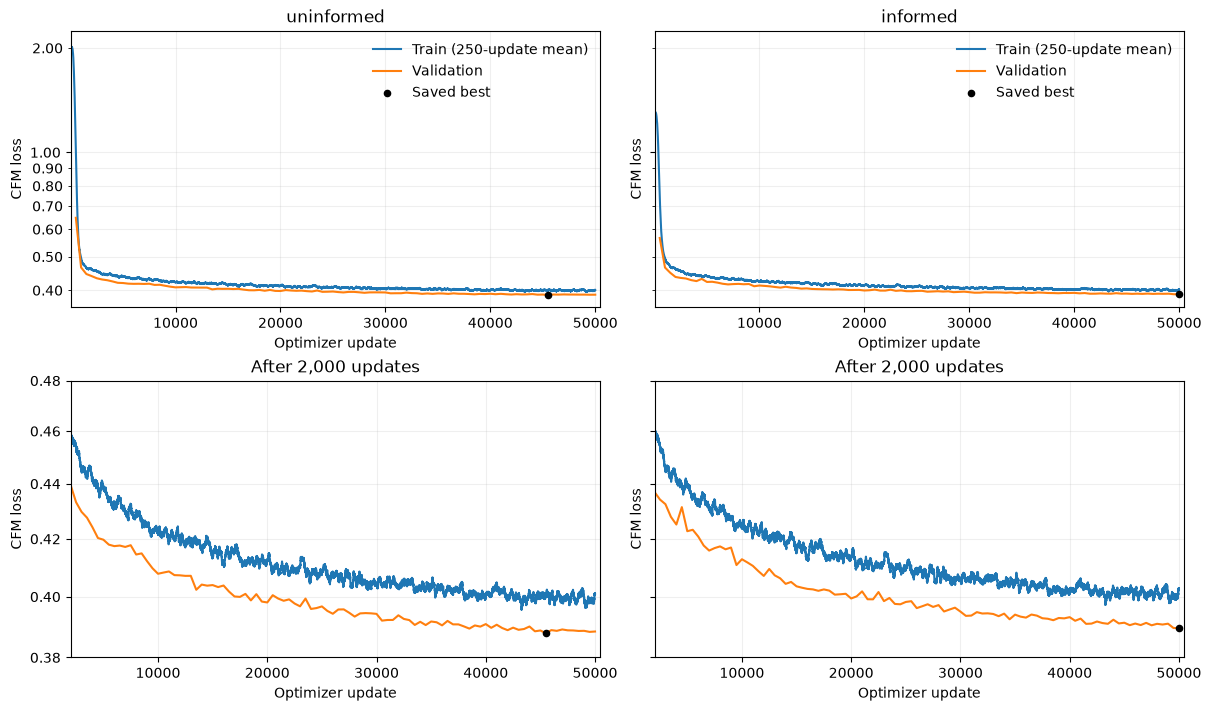

              updates  best_step  best_val  training_minutes  effective_batch
uninformed 50000.0000 45500.0000    0.3878           86.2802         128.0000
informed   50000.0000 50000.0000    0.3895           84.5255         128.0000


In [17]:
def plot_training(checkpoints: dict, window: int = 250, zoom_after: int = 2000) -> pd.DataFrame:
    """Plots full training histories and a closer view of convergence."""
    _, axes = plt.subplots(2, 2, figsize=(12, 7), sharey="row", layout="constrained")
    rows = {}
    for col, (label, saved) in enumerate(checkpoints.items()):
        history = pd.DataFrame(saved["history"])
        train = history["train"].rolling(window, min_periods=1).mean()
        val = history.dropna(subset=["val"])

        for row, start in enumerate((1, zoom_after)):
            ax = axes[row, col]
            keep = history["step"] >= start
            measured = val[val["step"] >= start]
            ax.plot(history.loc[keep, "step"], train[keep], label=f"Train ({window}-update mean)")
            ax.plot(measured["step"], measured["val"], label="Validation")
            ax.scatter(
                saved["step"], saved["val_loss"], color="black", s=20, zorder=3,
                label="Saved best",
            )
            ax.set(xlabel="Optimizer update", ylabel="CFM loss", yscale="log")
            ax.set_xlim(start, saved["trained_updates"] * 1.01)
            ax.yaxis.set_major_formatter("{x:.2f}")
            ax.yaxis.set_minor_formatter("{x:.2f}")
            ax.grid(which="both", alpha=0.2)
            ax.set_title(label if row == 0 else f"After {start:,} updates")
            if row == 0:
                ax.legend(frameon=False)

        rows[label] = {
            "updates": saved["trained_updates"],
            "best_step": saved["step"],
            "best_val": saved["val_loss"],
            "training_minutes": saved["seconds"] / 60,
            "effective_batch": saved["config"]["batch_size"] * saved["config"]["accumulation"],
        }

    low, high = axes[1, 0].get_ylim()
    ticks = np.arange(np.floor(low / 0.02), np.ceil(high / 0.02) + 1) * 0.02
    axes[1, 0].set_yticks(ticks)
    axes[1, 0].minorticks_off()
    axes[1, 1].minorticks_off()
    plt.show()

    table = pd.DataFrame(rows).T
    print(table.to_string(float_format=lambda value: f"{value:.4f}"))
    return table


checkpoints = {"uninformed": uninformed_saved, "informed": informed_saved}
training_table = plot_training(checkpoints)

In [20]:
@torch.no_grad()
def benchmark_inference(
    model: PedestrianFlow,
    observed: Tensor,
    valid: Tensor,
    informed: bool,
    sigma: float,
    steps: int = 10,
    warmup: int = 3,
    repeats: int = 20,
) -> dict:
    """Times float32 sampling; returns mean/std [ms], excluding data transfer."""
    if warmup < 0 or repeats < 1:
        raise ValueError("Warmup must be nonnegative and repeats must be positive")
    device = next(model.parameters()).device
    observed, valid = observed.to(device), valid.to(device)
    generator = torch.Generator(device=device).manual_seed(2026)
    for _ in range(warmup):
        sample_future(model, observed, valid, informed, generator, steps, sigma)
    times = []
    for _ in range(repeats):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        start = time.perf_counter()
        sample_future(model, observed, valid, informed, generator, steps, sigma)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        times.append(1000 * (time.perf_counter() - start))
    return {
        "batch_size": len(observed),
        "people": valid.sum(dim=1).tolist(),
        "steps": steps,
        "field_calls": 2 * steps,
        "repeats": repeats,
        "mean_ms": float(np.mean(times)),
        "std_ms": float(np.std(times)),
    }


loader = make_loader(dataset, SPLITS["val"][:4], batch_size=4, num_workers=0)
pos, valid = padded_batch(next(iter(loader)), torch.device("cpu"))
rows = {}
for informed, model in ((False, uninformed_model), (True, informed_model)):
    label = "informed" if informed else "uninformed"
    rows[label] = benchmark_inference(
        model, pos[:, :, :H], valid, informed, checkpoints[label]["config"]["sigma"], HEUN_STEPS
    )
inference_table = pd.DataFrame(rows).T
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE))
print(inference_table.to_string())

GPU: NVIDIA GeForce RTX 5070 Ti
           batch_size            people steps field_calls repeats    mean_ms    std_ms
uninformed          4  [14, 30, 22, 17]    10          20      20  39.456253  0.312455
informed            4  [14, 30, 22, 17]    10          20      20  39.685186  0.290743
